In [1]:
# --- 0. Setup: find the repo root wherever this notebook runs from ------------------------
import os, sys, json, unittest
from pathlib import Path
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "run_experiment.py").exists())
sys.path.insert(0, str(ROOT / "code"))
os.chdir(ROOT)                                  # so relative paths in configs resolve
print("Repo root:", ROOT)

import run_experiment, evaluate_final, summarise
from obpevo import config as C, core, instances, baselines

Repo root: c:\Users\nicho\Downloads\dsa4212-obp


In [2]:
# --- 6. Real LLM check with Gemini (free tier) ---------------------------------------------
# Check pipeline using pipeline.yaml first (12 evals, population 4)
# 6a. API key: from .env in the repo root (GEMINI_API_KEY=...), or paste it below. Never commit it.
try:
    from dotenv import load_dotenv                      # %pip install python-dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass
# os.environ["GEMINI_API_KEY"] = "AIza..."             # alternative: paste here, clear before sharing
assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is not set"

from obpevo.llm import make_backend

In [3]:
# One call through the same wrapper the pipeline uses
import tempfile
from obpevo.llm import make_backend, LoggedLLM
cfg = C.load("configs/eoh_baseline.yaml")
log = Path(tempfile.mkdtemp()) / "calls.csv"
wrapped = LoggedLLM(make_backend(cfg["llm"]), log, price_in_per_1m=0.3, price_out_per_1m=2.5)
print(wrapped.draw_sample("Say hi")[:100])
display(pd.read_csv(log))           # one row: status ok, token_source api

Hi!


,call,t_start,latency_s,prompt_tokens,completion_tokens,token_source,cum_tokens,cost_usd,status,prompt_chars,response_chars
0,1,1.792923e+09,1.913,3,2,api,5,0.000006,ok,6,3


LLM: gemini / gemini-3.5-flash-lite | budget: {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120} | methods: ['eoh']
32 training instances | Best Fit train excess: 4.751%
LLM: gemini / gemini-3.5-flash-lite
[eoh_baseline] 1 runs | budget {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120} | train=train (32 instances)
           eoh seed0: 300 evals (299 ok, 1 err, 0 timeout) | 301 calls, 206,658 tokens | best train excess 0.0379 | budget:evals | 34.22 min
Wrote C:\Users\nicho\Downloads\dsa4212-obp\results\eoh_baseline\runs_index.csv (1 runs)

stopped: budget:evals after 34.22 min
evals: {'ok': 299, 'error': 1} | LLM calls: 301 (0 failed)
tokens: 155,894 in + 50,764 out | notional cost $0.174
best train excess 3.788% vs Best Fit 4.751% (-0.964 pp; negative = EoH better) | found at eval 217


eval,30,60,90,120,150,180,210,240,270,300
best_so_far_%,4.751,4.751,4.751,4.751,4.751,4.085,4.085,3.788,3.788,3.788


# eval 217, train excess 0.03788

import numpy as np

def priority(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.
    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.
    Return:
        Array of same size as bins with priority score of each bin.
    """
    remaining = bins - item
    density = item / bins
    score = np.where(density < 0.5, np.exp(density) - np.log1p(remaining), np.power(density, 1.5) - remaining)
    return np.where(remaining >= 0, score, -np.inf)


[eoh_baseline] 8 program x set jobs on ['val', 'test_id_5k', 'test_size_10k', 'test_cap500', 'test_cap500_scaled', 'test_shape_k1.5', 'test_shape_k5', 'test_uniform']
               eoh seed0 val                ok
               eoh seed0 test_uniform       ok
               eoh seed0 test_id_5k         ok
               eoh seed0 test_cap500_scaled ok
               eoh seed0 test_cap500        ok
 

set,test_cap500,test_cap500_scaled,test_id_5k,test_shape_k1.5,test_shape_k5,test_size_10k,test_uniform,val
label,,,,,,,,
almost_worst_fit,0.90,8.82,8.44,6.63,10.47,8.34,8.30,8.24
best_fit,0.50,4.44,4.17,1.34,8.25,3.95,5.07,4.73
eoh,0.40,5.73,2.22,0.92,38.94,1.73,2.88,3.73
first_fit,0.50,4.80,4.55,1.58,8.45,4.27,5.57,5.23
next_fit,4.62,29.43,29.20,30.06,24.32,28.96,31.71,28.63
worst_fit,2.34,13.72,13.14,12.27,12.95,13.01,14.46,13.34


c:\Users\nicho\Downloads\dsa4212-obp\code\summarise.py:118: RuntimeWarning: All-NaN slice encountered
  med, lo, hi = np.nanmedian(c, 0), np.nanmin(c, 0), np.nanmax(c, 0)


# eoh_baseline: summary tables

Budget per run: {'max_evals': 300, 'max_tokens': 1500000, 'max_minutes': 120}

## Search runs

| label | runs | evals/run | ok % | error % | timeout % | LLM calls/run | tokens/run | cost USD (total) | minutes/run | best train excess % (mean ± sd) |
|---|---|---|---|---|---|---|---|---|---|---|
| eoh | 1 | 300.0 | 99.7 | 0.3 | 0.0 | 301.0 | 206658 | 0.174 | 34.22 | 3.788 ± 0.000 |

## Held-out sets: excess over lower bound (%), mean ± sd across seeds

| label | val | test_id_5k | test_size_10k | test_cap500 | test_cap500_scaled | test_shape_k1.5 | test_shape_k5 | test_uniform |
|---|---|---|---|---|---|---|---|---|
| eoh | 3.73 | 2.22 | 1.73 | 0.40 | 5.73 | 0.92 | 38.95 | 2.88 |
| first_fit | 5.23 | 4.55 | 4.27 | 0.50 | 4.80 | 1.58 | 8.45 | 5.57 |
| best_fit | 4.73 | 4.17 | 3.95 | 0.50 | 4.44 | 1.34 | 8.25 | 5.07 |
| worst_fit | 13.34 | 13.14 | 13.01 | 2.34 | 13.72 | 12.27 | 12.95 | 14.46 |
| almost_worst_fit | 8.24 | 8.44 | 8.34 | 0.90 | 8.82 | 6.63 | 10

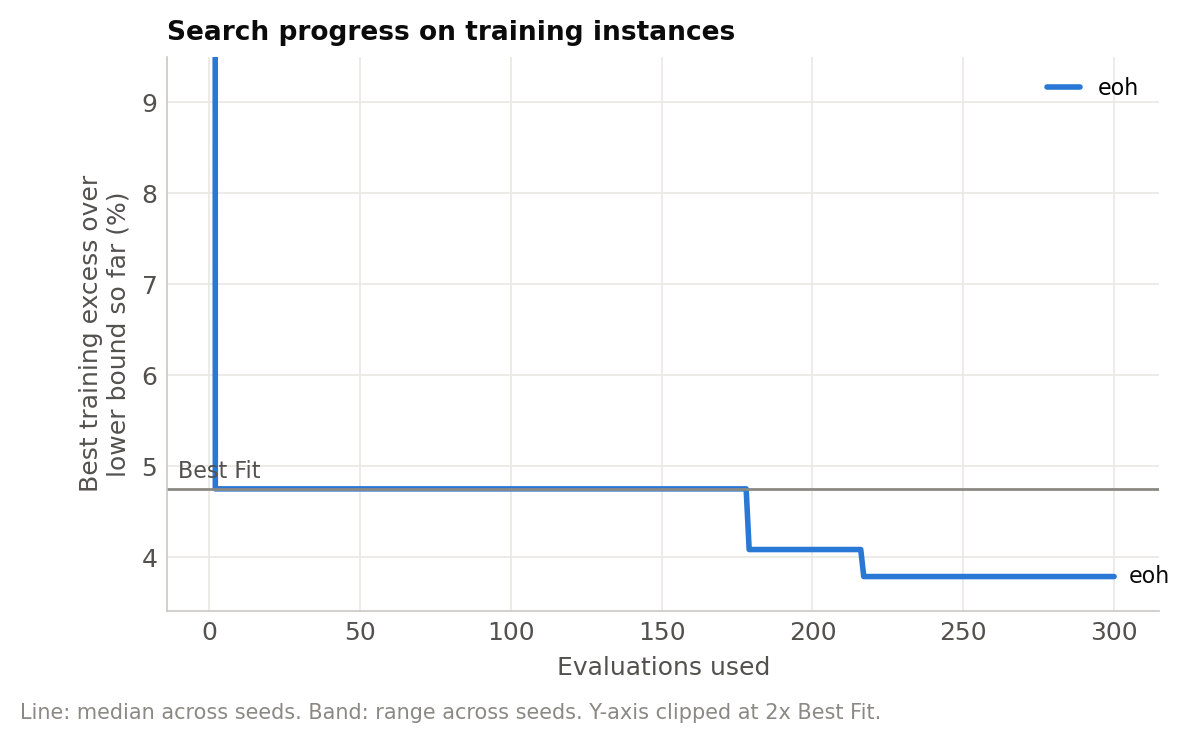

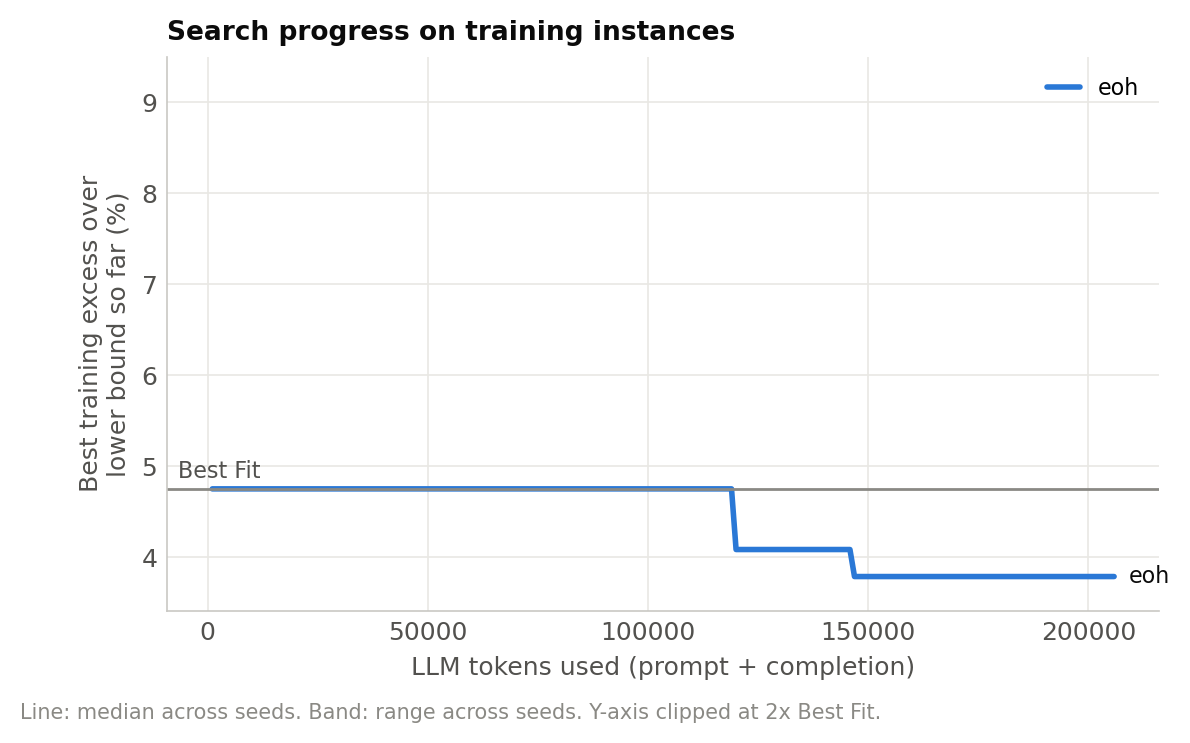

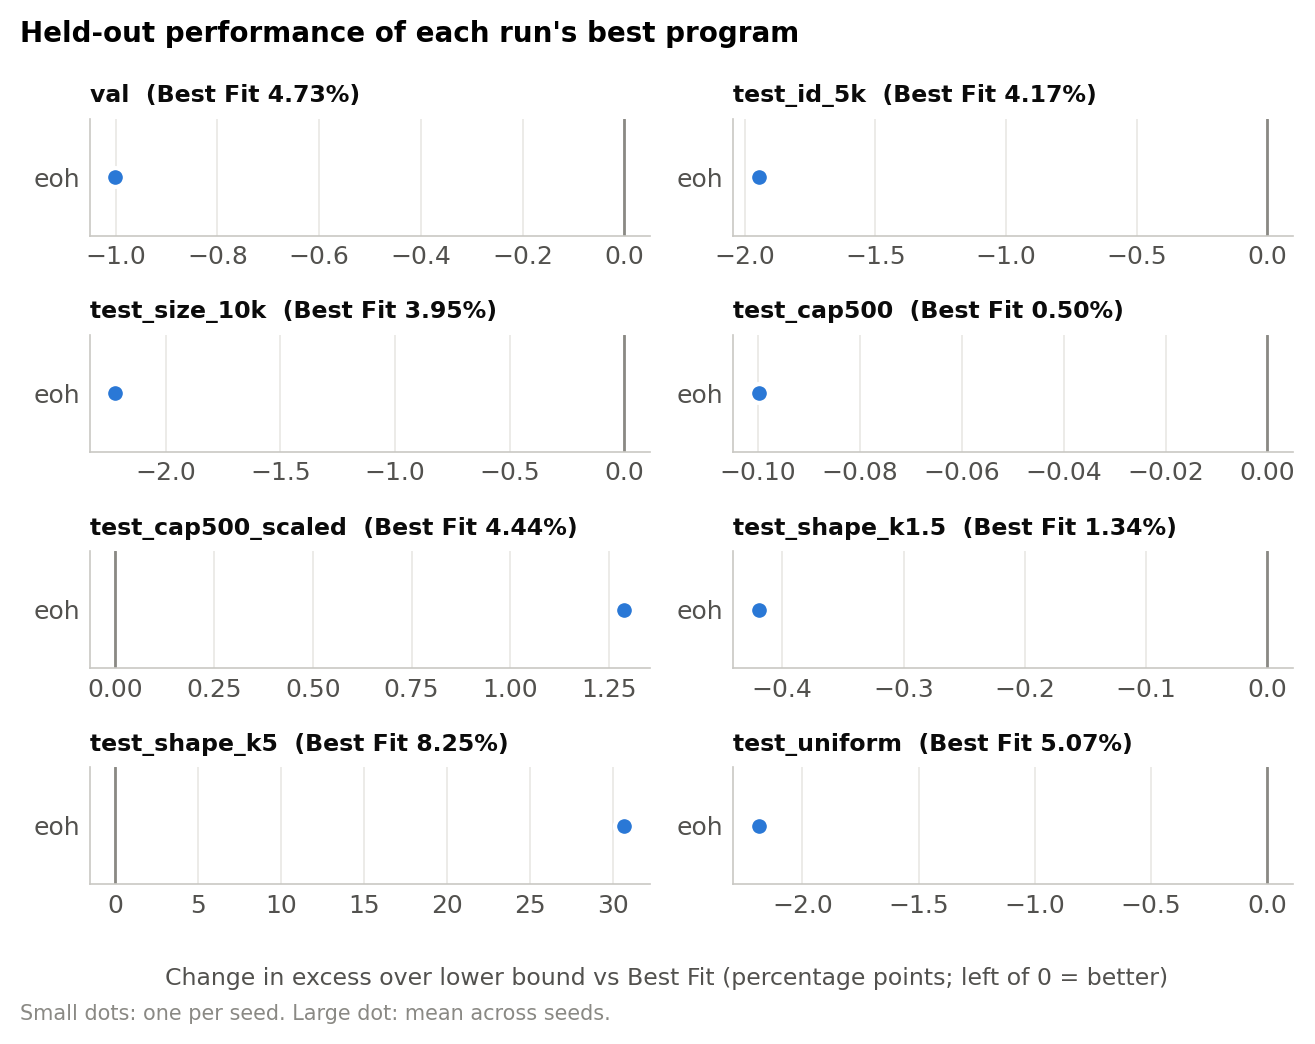

In [4]:
# --- 7. EoH baseline: one full seed on the real instances ----------------------------------
# ~300 evals, ~330 LLM calls, ~25-40 min, well under US$1 notional. Needs steps 0 and 6a (API key) first.
CONFIG = "configs/eoh_baseline.yaml"
SEED = 0                                                # run 0 first; then 1 and 2 (e.g. on later days)
OV = {}                                                 # e.g. {"budget": {"max_evals": 100}} for a shorter run
cfg = C.load(CONFIG, OV)
print("LLM:", cfg["llm"]["provider"], "/", cfg["llm"]["model"], "| budget:", cfg["budget"],
      "| methods:", [m["label"] for m in cfg["methods"]])

# 7a. Best Fit on the real training set: the number EoH has to beat
train_v0 = instances.load_set(run_experiment.ensure_instances(cfg) / f"{cfg['evaluation']['train_set']}.npz")
bf_v0 = -core.score(core.evaluate(baselines.best_fit, train_v0, cfg["evaluation"]["mode"]))
print(f"{len(train_v0)} training instances | Best Fit train excess: {bf_v0:.3%}")

# 7b. The search (the cell blocks until it finishes; finished seeds are skipped unless force=True)
# idx = run_experiment.main(CONFIG, seeds=[SEED], overrides=OV)
idx = run_experiment.main(CONFIG, seeds=[SEED], overrides=OV, force=True)
run = C.results_dir(cfg) / "eoh" / f"seed{SEED}"
s = json.loads((run / "summary.json").read_text())
evals = pd.read_csv(run / "evals.csv")
calls = pd.read_csv(run / "llm_calls.csv")

# 7c. How the run went
print(f"\nstopped: {s['stop_reason']} after {s['wall_minutes']} min")   # budget:evals is the normal ending
print(f"evals: {evals.status.value_counts().to_dict()} | LLM calls: {len(calls)} ({(calls.status != 'ok').sum()} failed)")
print(f"tokens: {calls.prompt_tokens.sum():,} in + {calls.completion_tokens.sum():,} out | notional cost ${calls.cost_usd.sum():.3f}")
if s["best_train_excess"] is None:                     # no candidate ran successfully
    print("No successful candidate: see the diagnostics cell")
else:
    print(f"best train excess {s['best_train_excess']:.3%} vs Best Fit {bf_v0:.3%} "
          f"({(s['best_train_excess'] - bf_v0) * 100:+.3f} pp; negative = EoH better) | found at eval {s['best_eval']}")
if s["stop_reason"] == "budget:llm_errors":             # API kept failing, e.g. free-tier daily quota
    print("API errors:", calls[calls.status != "ok"].status.str[:120].value_counts().head(3).to_dict())

# Best-so-far at 10 points through the run: is the search still improving at the end?
evals["best_so_far_%"] = evals.train_excess.cummin().ffill() * 100
step = max(1, len(evals) // 10)
display(evals.iloc[step - 1::step][["eval", "best_so_far_%"]].round(3).set_index("eval").T)

print((run / "best_program.py").read_text())

# 7d. Held-out evaluation on all 8 sets, tables and figures
summ = evaluate_final.main(CONFIG, overrides=OV)
display((summ.pivot(index="label", columns="set", values="mean_excess") * 100).round(2))   # % over lower bound
figs = summarise.main(CONFIG, overrides=OV)
from IPython.display import Image
for name in ["convergence_evals", "convergence_tokens", "test_sets"]:
    display(Image(figs / f"{name}.png", width=650))

In [5]:
# # Why did no candidate succeed?
# print("stop reason:", s["stop_reason"], "| evals:", s["n_evals"], "| LLM calls:", s["n_llm_calls"],
#       "| minutes:", s["wall_minutes"])
# display(calls[["call", "latency_s", "status"]].tail(8))                    # did the API calls work?
# display(evals[["eval", "status", "wall_s", "error"]].head(10))             # did the candidates run?
# err = run / "error.txt"
# print(err.read_text()[-2000:] if err.exists() else "no error.txt") 

In [6]:
# import traceback
# from obpevo.llm import make_backend
# try:
#     print(make_backend(cfg["llm"]).complete("Say hi")[0][:200])
# except Exception:
#     traceback.print_exc()